Dataset Loaded Successfully!
Dataset Shape: (374661, 19)

Attack Type Distribution:
Attack type
Normal       340066
Grayhole      14596
Blackhole     10049
TDMA           6638
Flooding       3312
Name: count, dtype: int64

Available Classes:
Attack type
Normal       340066
Grayhole      14596
Blackhole     10049
TDMA           6638
Flooding       3312
Name: count, dtype: int64

Model Training Completed!

Model Accuracy: 98.92 %

Classification Report:
              precision    recall  f1-score   support

   Blackhole       0.99      0.99      0.99      2010
    Flooding       0.92      0.96      0.94       662
    Grayhole       0.90      0.99      0.94      2919
      Normal       1.00      0.99      0.99     68014
        TDMA       0.82      0.94      0.87      1328

    accuracy                           0.99     74933
   macro avg       0.92      0.97      0.95     74933
weighted avg       0.99      0.99      0.99     74933



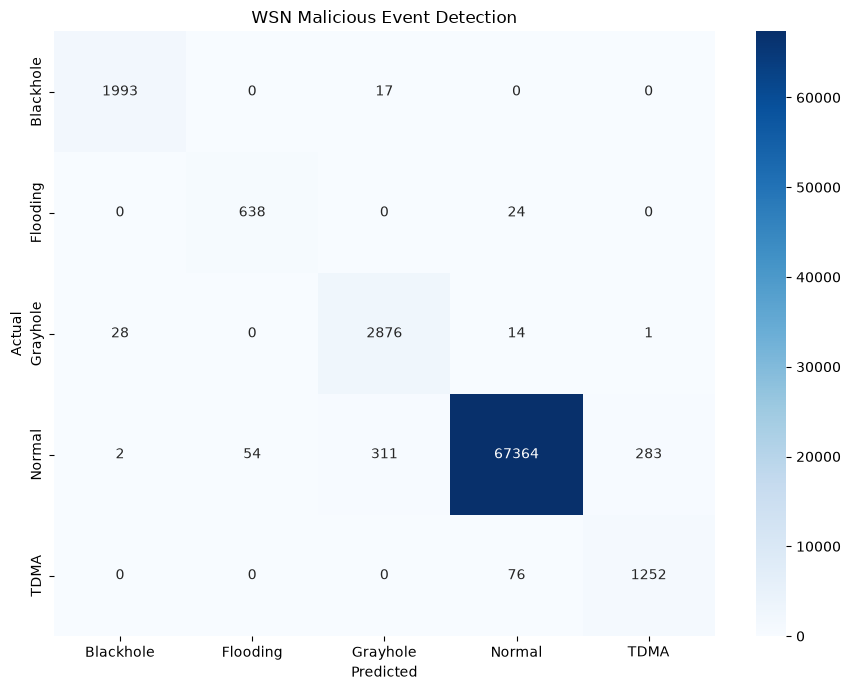


Sample Predictions:
      Actual  Predicted
0     Normal     Normal
1     Normal     Normal
2     Normal     Normal
3     Normal     Normal
4  Blackhole  Blackhole
5     Normal     Normal
6     Normal     Normal
7     Normal     Normal
8     Normal     Normal
9     Normal     Normal

Results saved successfully!


In [2]:
# Program 12: Wireless Sensor Network Malicious Event Detection

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report, confusion_matrix

# Step 1: Load Dataset
df = pd.read_csv("WSN-DS.csv", low_memory=False)

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

# Step 2: Clean Column Names
df.columns = df.columns.str.strip()

# Step 3: Identify Target Column
target_column = next(
    (col for col in df.columns
     if col.strip().lower() == 'attack type'),
    None
)

if target_column is None:
    raise ValueError("Attack type column not found!")

# Step 4: Clean Target Values
df = df.dropna(subset=[target_column]).copy()

df[target_column] = (
    df[target_column].astype(str).str.strip()
)

print("\nAttack Type Distribution:")
print(df[target_column].value_counts())

# Step 5: Remove Unnecessary Columns
drop_columns = [
    target_column,
    'Id',
    'Who CH'
]

drop_columns = [
    col for col in drop_columns if col in df.columns
]

# Step 6: Select Features
X = df.drop(columns=drop_columns)

# Keep numerical features
X = X.select_dtypes(include=[np.number])

# Remove invalid values
X = X.replace([np.inf, -np.inf], np.nan)

# Remove rows containing missing feature values
valid_index = X.dropna().index

X = X.loc[valid_index].copy()
y = df.loc[valid_index, target_column].copy()

if X.empty:
    raise ValueError("No valid numerical features found.")

# Step 7: Display Class Distribution
print("\nAvailable Classes:")
print(y.value_counts())

# Step 8: Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Step 9: Create Decision Tree Model
model = DecisionTreeClassifier(
    max_depth=15,
    random_state=42,
    class_weight='balanced'
)

# Step 10: Train Model
model.fit(X_train, y_train)

print("\nModel Training Completed!")

# Step 11: Predict Results
y_pred = model.predict(X_test)

# Step 12: Calculate Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy:",
      round(accuracy * 100, 2), "%")

# Step 13: Classification Report
print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

# Step 14: Confusion Matrix
labels = model.classes_

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("WSN Malicious Event Detection")
plt.tight_layout()
plt.show()

# Step 15: Save Results
results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

results.to_csv(
    "wsn_detection_results.csv",
    index=False
)

print("\nSample Predictions:")
print(results.head(10))

print("\nResults saved successfully!")